# DS201 · LAB 4: ENCODER–DECODER VÀ ATTENTION CHO DỊCH MÁY


## Phần A. Chuẩn bị trước buổi học

### Nạp thư viện và đặt cấu hình

Dùng kernel Python 3.12. `cfg` là cấu hình duy nhất của notebook: giá trị mặc định là mạng nhỏ trên tập con để chạy kịp trong giờ học. Khi làm Phần C, đổi các giá trị có chú thích `Phần C` rồi Restart Kernel và Run All.

In [2]:
# Import thư viện
import hashlib, json, random, time, unicodedata, urllib.request
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn.utils.rnn import (
    pad_sequence, pack_padded_sequence, pad_packed_sequence,
)
from torch.utils.data import DataLoader
from rouge_score import rouge_scorer
from sacrebleu.metrics import BLEU

In [3]:
# Cố định seed và chọn thiết bị
def seed_all(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_all()
torch.set_num_threads(min(4, torch.get_num_threads()))
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| device:', device)

PyTorch: 2.14.1+cpu | device: cpu


In [4]:
# Cấu hình chung; Phần C đổi các giá trị có chú thích "Phần C"
cfg = dict(
    emb=64, hidden=64, layers=1,  # Phần C: 256, 256, 3
    dropout=0.3, batch=32, lr=1e-3, teacher_ratio=0.5,
    epochs=3,                     # Phần C: 10
    max_words=25,                 # Phần C: 50
    vocab_limit=3000,             # Phần C: 10000
    min_freq=2,
    train_limit=512,              # Phần C: None (toàn bộ train)
    dev_limit=64,                 # Phần C: None (toàn bộ dev)
)
for k, v in cfg.items():
    print(f'{k:14}= {v}')

emb           = 64
hidden        = 64
layers        = 1
dropout       = 0.3
batch         = 32
lr            = 0.001
teacher_ratio = 0.5
epochs        = 3
max_words     = 25
vocab_limit   = 3000
min_freq      = 2
train_limit   = 512
dev_limit     = 64


In [5]:
# Đường dẫn dữ liệu, thư mục lưu kết quả và id của 4 token đặc biệt
base = Path.cwd()
LAB = base/'Lab4' if (base/'Lab4').is_dir() else base
DATA = LAB/'data'
ART = LAB/'artifacts'
ART.mkdir(parents=True, exist_ok=True)
PAD, UNK, BOS, EOS = 0, 1, 2, 3
print('Dữ liệu:', DATA.name, '| kết quả lưu ở:', ART.name)

Dữ liệu: data | kết quả lưu ở: artifacts


### Tải đúng ba tệp small-PhoMT

Dữ liệu lấy trực tiếp từ thư mục trong đề gốc. Tệp đã có trên máy được kiểm tra SHA-256 trước khi dùng lại. Không thay bằng bộ chia khác hoặc dữ liệu giả khi không tải được.

In [6]:
# Danh sách tệp: tên, link tải và mã SHA-256
DATA_FILES = [{'file': 'small-train.json',
  'url': 'https://drive.google.com/uc?export=download&id=1-eG6FeF-v__rsf77iWurddahXbyjTYh5',
  'sha256': 'f643c83f1ce3c9781eb5e03ed3ea56406abd4d877fde965d60c0a213d3906cba'},
 {'file': 'small-dev.json',
  'url': 'https://drive.google.com/uc?export=download&id=1hoTd2hFwjSeFThlPm6YpN0NW5ePXS3Jc',
  'sha256': 'fceab11b93c92167887c90f22ccc2f08c9ac8cb1c7786decc544ae90de1c23f9'},
 {'file': 'small-test.json',
  'url': 'https://drive.google.com/uc?export=download&id=1_3L25SH1_jaEfOjpmpgnfMik4N3MxSyn',
  'sha256': '1c63903af344ead37b85e2a51487e71bf44c0ceed7797b5979a9551282d83d1a'}]

In [7]:
# Tải tệp còn thiếu, rồi kiểm tra SHA-256 của cả ba tệp
for item in DATA_FILES:
    path = DATA/item['file']
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        with urllib.request.urlopen(item['url'], timeout=90) as r:
            content = r.read()
        if hashlib.sha256(content).hexdigest() != item['sha256']:
            raise ValueError('Nguồn tải đổi hoặc trả về HTML: '+item['file'])
        path.write_bytes(content)
    if hashlib.sha256(path.read_bytes()).hexdigest() != item['sha256']:
        raise ValueError('Checksum không khớp: '+item['file'])
print('3/3 tệp dữ liệu khớp SHA-256.')

3/3 tệp dữ liệu khớp SHA-256.


### Chuẩn hóa Unicode và lọc theo độ dài

Mỗi tệp là JSON array gồm `english` và `vietnamese`. Loại BOM, chuẩn hóa NFC, chuyển chữ thường rồi tách theo khoảng trắng. Chỉ giữ cặp có cả hai phía từ 1 đến `max_words` token; không cắt cụt câu đích.

In [ ]:
# Chuẩn hóa: bỏ BOM, NFC, chữ thường, tách theo khoảng trắng
def tokens(text):
    text = unicodedata.normalize('NFC', text.replace('﻿', ''))
    return text.lower().split()

print(tokens('Tôi YÊU bạn'))

['tôi', 'yêu', 'bạn']


In [ ]:
# Đọc ba tệp, giữ cặp có cả hai phía dài từ 1 đến max_words token
raw, filtered = {}, {}
for split in ['train', 'dev', 'test']:
    path = DATA/f'small-{split}.json'
    raw[split] = json.loads(path.read_text(encoding='utf-8-sig'))
    filtered[split] = []
    for i, row in enumerate(raw[split]):
        source, target = tokens(row['english']), tokens(row['vietnamese'])
        if 1 <= len(source) <= cfg['max_words'] and \
                1 <= len(target) <= cfg['max_words']:
            filtered[split].append(dict(id=i, src=source, tgt=target))
    print(split, '| tệp gốc:', len(raw[split]),
          '| sau lọc:', len(filtered[split]))

train | tệp gốc: 20000 | sau lọc: 12836
dev | tệp gốc: 2000 | sau lọc: 1172
test | tệp gốc: 2000 | sau lọc: 1003


In [ ]:
# Kiểm tra số cặp của ba bộ chia gốc
assert [len(raw[s]) for s in raw] == [20000, 2000, 2000]
assert all(filtered[s] for s in filtered)
print('Đúng schema và ba bộ chia gốc: PASS')

Đúng schema và ba bộ chia gốc: PASS


## B.1. Từ điển, batch và nhãn đích

### Xây hai từ điển từ tập train

Hai ngôn ngữ có từ điển riêng nhưng cùng quy ước PAD/UNK/BOS/EOS. Từ điển chỉ xây từ train sau lọc, không dùng dev/test. `vocab_limit` tính cả bốn token đặc biệt.

In [ ]:
# Hàm xây từ điển: 4 token đặc biệt + token xuất hiện ít nhất min_freq lần
SPECIAL = ['<pad>', '<unk>', '<bos>', '<eos>']
def make_vocab(sequences):
    freq = Counter(t for seq in sequences for t in seq)
    ranked = sorted(freq, key=lambda t: (-freq[t], t))
    keep = [t for t in ranked if freq[t] >= cfg['min_freq']
            and t not in SPECIAL][:cfg['vocab_limit']-4]
    return {token: i for i, token in enumerate(SPECIAL+keep)}

In [ ]:
# Từ điển tiếng Anh (nguồn) và tiếng Việt (đích)
src_vocab = make_vocab(r['src'] for r in filtered['train'])
tgt_vocab = make_vocab(r['tgt'] for r in filtered['train'])
tgt_itos = {i: t for t, i in tgt_vocab.items()}
assert all(src_vocab[t] == tgt_vocab[t] == i
           for i, t in enumerate(SPECIAL))
print('Từ điển Anh/Việt:', len(src_vocab), len(tgt_vocab))
print('Special IDs:', {t: src_vocab[t] for t in SPECIAL})

Từ điển Anh/Việt: 3000 2998
Special IDs: {'<pad>': 0, '<unk>': 1, '<bos>': 2, '<eos>': 3}


In [ ]:
# Đổi token thành id; token chưa có trong từ điển phải thành UNK
def encode(seq, vocab):
    return [vocab.get(t, UNK) for t in seq]

assert encode(['từ_không_có_thật'], tgt_vocab) == [UNK]
print('encode:', encode(['tôi', 'từ_không_có_thật'], tgt_vocab))

encode: [6, 1]


### Dịch nhãn một bước và tạo batch

Câu nguồn kết thúc bằng EOS. Câu đích có BOS ở đầu và EOS ở cuối: decoder đọc `tgt[:, :-1]` để dự đoán `tgt[:, 1:]`. Giữ độ dài thật của câu nguồn trước khi đệm. Câu tham chiếu để chấm điểm giữ nguyên token đã chuẩn hóa, không đổi từ lạ thành UNK.

In [ ]:
# Ghép batch: nguồn thêm EOS, đích thêm BOS/EOS, đệm PAD bên phải
def collate(rows):
    src = [torch.tensor(encode(r['src'], src_vocab)+[EOS]) for r in rows]
    tgt = [torch.tensor([BOS]+encode(r['tgt'], tgt_vocab)+[EOS])
           for r in rows]
    return dict(
        src=pad_sequence(src, batch_first=True, padding_value=PAD),
        lengths=torch.tensor([len(x) for x in src]),
        tgt=pad_sequence(tgt, batch_first=True, padding_value=PAD),
        refs=[' '.join(r['tgt']) for r in rows],
        ids=[r['id'] for r in rows],
    )

In [ ]:
# Thử trên hai cặp câu tự tạo
toy = [dict(id=-1, src=tokens('i love you'), tgt=tokens('tôi yêu bạn')),
       dict(id=-2, src=tokens('hello'), tgt=tokens('xin chào'))]
batch = collate(toy)
print('src:', tuple(batch['src'].shape),
      '| lengths:', batch['lengths'].tolist())
print('tgt:', tuple(batch['tgt'].shape))

src: (2, 4) | lengths: [4, 2]
tgt: (2, 5)


In [ ]:
# Decoder đọc tgt[:, :-1] để dự đoán tgt[:, 1:] (lệch một bước)
decoder_input = [tgt_itos[i] for i in batch['tgt'][0, :-1].tolist()]
target = [tgt_itos[i] for i in batch['tgt'][0, 1:].tolist()]
print('decoder input:', decoder_input)
print('target       :', target)
assert batch['tgt'][:, :-1].shape == batch['tgt'][:, 1:].shape

decoder input: ['<bos>', 'tôi', 'yêu', 'bạn']
target       : ['tôi', 'yêu', 'bạn', '<eos>']


### Chọn tập con và tạo DataLoader

Lấy ngẫu nhiên `train_limit=512` cặp train và `dev_limit=64` cặp dev với seed 42 để chạy nhanh; Phần C đặt hai giá trị này bằng `None` để dùng toàn bộ. Ba mô hình dùng cùng tập và cùng thứ tự batch. Test không được dùng trong lúc phát triển.

In [ ]:
# Lấy tập con cố định theo seed 42; limit=None nghĩa là dùng toàn bộ
def choose(rows, limit):
    if limit is None or len(rows) <= limit:
        return rows
    ids = np.random.default_rng(42).permutation(len(rows))[:limit]
    return [rows[int(i)] for i in ids]

train_rows = choose(filtered['train'], cfg['train_limit'])
dev_rows = choose(filtered['dev'], cfg['dev_limit'])
print('Train/dev đang dùng:', len(train_rows), len(dev_rows))

Train/dev đang dùng: 512 64


In [ ]:
# DataLoader có generator cố định để thứ tự batch giống nhau giữa các mô hình
def loader(rows, shuffle=False):
    return DataLoader(rows, batch_size=cfg['batch'], shuffle=shuffle,
                      collate_fn=collate,
                      generator=torch.Generator().manual_seed(42))

print('Số batch train mỗi epoch:', len(loader(train_rows)))

Số batch train mỗi epoch: 16


## B.2. Encoder và các trạng thái LSTM

### Encoder trả toàn bộ memory và hai trạng thái cuối

Encoder một chiều đọc cả câu nguồn bằng LSTM có packing. Đầu ra gồm `memory` [B, S, H] cho attention và `(h, c)` [K, B, H] để khởi tạo decoder. Encoder và decoder cùng số lớp, cùng hidden size nên truyền thẳng cả h và c.

In [ ]:
# Encoder: Embedding -> LSTM có packing; trả memory và (h, c)
class Encoder(nn.Module):
    def __init__(self, vocab_size, emb, hidden, layers, dropout):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.drop = nn.Dropout(dropout)
        self.rnn = nn.LSTM(emb, hidden, layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0)

    def forward(self, src, lengths):
        packed = pack_padded_sequence(
            self.drop(self.emb(src)), lengths.cpu(),
            batch_first=True, enforce_sorted=False)
        packed_out, state = self.rnn(packed)
        memory, _ = pad_packed_sequence(
            packed_out, batch_first=True, total_length=src.size(1))
        return memory, state

In [ ]:
# Chạy thử encoder trên batch tự tạo và xem shape
model_cfg = {k: cfg[k] for k in ['emb', 'hidden', 'layers', 'dropout']}
encoder = Encoder(len(src_vocab), **model_cfg).to(device)
memory, (h, c) = encoder(batch['src'].to(device), batch['lengths'])
print('memory:', tuple(memory.shape))
print('h/c:', tuple(h.shape), tuple(c.shape))

memory: (2, 4, 64)
h/c: (1, 2, 64) (1, 2, 64)


## B.3. Attention cộng, attention general và masking

### Tính softmax và context bằng tay

Ví dụ tự tạo có ba điểm 0,5; 2; −1. Attention chuẩn hóa điểm theo chiều câu nguồn rồi lấy tổng có trọng số của các value. Context thay đổi theo query ở từng bước giải mã, không thay cho cell state của LSTM.

In [ ]:
# Điểm attention tự tạo -> trọng số alpha bằng softmax
scores = torch.tensor([[0.5, 2.0, -1.0]])
alpha = torch.softmax(scores, dim=-1)
print('alpha:', [round(v, 6) for v in alpha[0].tolist()])
print('Tổng:', round(alpha.sum().item(), 6))

alpha: [0.17529, 0.785597, 0.039113]
Tổng: 1.0


In [ ]:
# Context = tổng có trọng số của các value
values = torch.tensor([[[1., 0.], [0., 1.], [1., 1.]]])
context = torch.bmm(alpha.unsqueeze(1), values).squeeze(1)
print('context:', [round(v, 6) for v in context[0].tolist()])

context: [0.214403, 0.82471]


### Cài additive và general attention có mask

Bahdanau dùng vᵀtanh(Wq + Uk); Luong ở đây dùng dạng general qᵀWk. `mask=True` tại token thật; vị trí PAD được gán −inf trước softmax nên nhận trọng số 0. Value là `memory` của encoder. Mỗi câu luôn có EOS nên không có hàng bị che hoàn toàn.

In [ ]:
# Hai kiểu tính điểm: Bahdanau (cộng) và Luong general (nhân)
class Attention(nn.Module):
    def __init__(self, hidden, mode):
        super().__init__()
        self.mode = mode
        if mode == 'bahdanau':
            self.Wq = nn.Linear(hidden, hidden, bias=False)
            self.Wk = nn.Linear(hidden, hidden, bias=False)
            self.v = nn.Linear(hidden, 1, bias=False)
        elif mode == 'luong':
            self.W = nn.Linear(hidden, hidden, bias=False)
        else:
            raise ValueError(mode)

    def forward(self, query, memory, mask):
        if self.mode == 'bahdanau':
            energy = torch.tanh(self.Wq(query).unsqueeze(1)
                                + self.Wk(memory))
            scores = self.v(energy).squeeze(-1)
        else:
            scores = torch.bmm(self.W(memory),
                               query.unsqueeze(2)).squeeze(2)
        scores = scores.masked_fill(~mask, float('-inf'))
        weights = torch.softmax(scores, dim=-1)
        context = torch.bmm(weights.unsqueeze(1), memory).squeeze(1)
        return context, weights

In [ ]:
# Kiểm tra: trọng số mỗi câu cộng bằng 1 và bằng 0 tại vị trí PAD
mask = batch['src'].to(device) != PAD
for mode in ['bahdanau', 'luong']:
    attn = Attention(cfg['hidden'], mode).to(device)
    context, weights = attn(h[-1], memory, mask)
    ones = torch.ones(len(toy), device=device)
    assert torch.allclose(weights.sum(-1), ones)
    assert torch.all(weights.masked_select(~mask) == 0)
    print(mode, '| context:', tuple(context.shape), '| mask: PASS')

bahdanau | context: (2, 64) | mask: PASS
luong | context: (2, 64) | mask: PASS


## B.4. Decoder, teacher forcing và giải mã greedy

### Phân biệt vị trí attention trong decoder

Không attention: LSTM chỉ nhận embedding. Bahdanau: query là h của bước trước, context được nối vào embedding trước khi vào LSTM. Luong global-general: LSTM cập nhật trước, dùng h hiện tại làm query, rồi ghép context với output qua tanh; vector này được đưa vào bước sau (input-feeding).

In [ ]:
# Decoder chạy từng bước; mode = 'none', 'bahdanau' hoặc 'luong'
class Decoder(nn.Module):
    def __init__(self, vocab_size, mode, emb, hidden, layers, dropout):
        super().__init__()
        self.mode = mode
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.drop = nn.Dropout(dropout)
        width = emb if mode == 'none' else emb + hidden
        self.rnn = nn.LSTM(width, hidden, layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0)
        if mode != 'none':
            self.attn = Attention(hidden, mode)
            self.fuse = nn.Linear(2*hidden, hidden)
        self.head = nn.Linear(hidden, vocab_size)

    def step(self, token, state, memory, mask, feeding):
        embedded = self.drop(self.emb(token))
        weights = None
        if self.mode == 'bahdanau':
            context, weights = self.attn(state[0][-1], memory, mask)
            rnn_input = torch.cat([embedded, context], dim=-1)
        elif self.mode == 'luong':
            rnn_input = torch.cat([embedded, feeding], dim=-1)
        else:
            rnn_input = embedded
        out, state = self.rnn(rnn_input.unsqueeze(1), state)
        query = out[:, 0]
        if self.mode == 'luong':
            context, weights = self.attn(query, memory, mask)
        if self.mode != 'none':
            feeding = torch.tanh(self.fuse(torch.cat([query, context], -1)))
            query = feeding
        logits = self.head(self.drop(query))
        return logits, state, feeding, weights

In [ ]:
# So số tham số decoder của ba kiểu
for mode in ['none', 'bahdanau', 'luong']:
    decoder = Decoder(len(tgt_vocab), mode, **model_cfg)
    print(f'{mode:9}| tham số decoder:',
          sum(p.numel() for p in decoder.parameters()))

none     | tham số decoder: 420022


bahdanau | tham số decoder: 452918
luong    | tham số decoder: 448758


### Ghép mô hình và teacher forcing đúng một bước

Khi huấn luyện, `forward` nhận cả câu đích; teacher forcing quyết định token đưa vào bước tiếp theo là token đúng hay token mô hình vừa dự đoán. Logits dự đoán câu đích từ vị trí 1, không chấm lại token vừa đưa vào.

In [ ]:
# Seq2Seq = Encoder + Decoder; teacher_ratio là xác suất dùng token đúng
class Seq2Seq(nn.Module):
    def __init__(self, mode, src_size, tgt_size, **kwargs):
        super().__init__()
        self.mode = mode
        self.encoder = Encoder(src_size, **kwargs)
        self.decoder = Decoder(tgt_size, mode, **kwargs)
        self.hidden = kwargs['hidden']

    def forward(self, src, lengths, tgt, teacher_ratio=0.5):
        memory, state = self.encoder(src, lengths)
        mask = src != PAD
        token = tgt[:, 0]
        feeding = memory.new_zeros(src.size(0), self.hidden)
        logits = []
        for t in range(1, tgt.size(1)):
            step, state, feeding, _ = self.decoder.step(
                token, state, memory, mask, feeding)
            logits.append(step)
            coin = torch.rand(src.size(0), device=src.device)
            predicted = step.argmax(-1).detach()
            token = torch.where(coin < teacher_ratio, tgt[:, t], predicted)
        return torch.stack(logits, dim=1)

In [ ]:
# Kiểm tra shape logits của ba mô hình
def make_seq2seq(mode, **kwargs):
    kwargs = kwargs or model_cfg
    return Seq2Seq(mode, len(src_vocab), len(tgt_vocab), **kwargs).to(device)

for mode in ['none', 'bahdanau', 'luong']:
    seed_all()
    model = make_seq2seq(mode)
    logits = model(batch['src'].to(device), batch['lengths'],
                   batch['tgt'].to(device), teacher_ratio=1.0)
    assert logits.shape[:2] == batch['tgt'][:, 1:].shape
    print(mode, '| logits:', tuple(logits.shape))

none | logits: (2, 4, 2998)
bahdanau | logits: (2, 4, 2998)
luong | logits: (2, 4, 2998)


### Giải mã greedy không nhận câu đích

Hàm `generate` chỉ nhận câu nguồn, độ dài và số bước tối đa. Mỗi câu dừng riêng khi gặp EOS; `finished` phải tích lũy qua các bước. ROUGE-L luôn tính trên câu sinh bằng `generate`, không đưa câu đích vào decoder.

In [ ]:
# Sinh từng token bằng argmax đến khi mọi câu gặp EOS hoặc hết max_steps
@torch.no_grad()
def generate(model, src, lengths, max_steps):
    model.eval()
    memory, state = model.encoder(src, lengths)
    mask = src != PAD
    token = torch.full((src.size(0),), BOS, device=src.device)
    feeding = memory.new_zeros(src.size(0), model.hidden)
    finished = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
    outputs, all_weights = [], []
    for _ in range(max_steps):
        logits, state, feeding, weights = model.decoder.step(
            token, state, memory, mask, feeding)
        logits[:, [PAD, BOS]] = float('-inf')
        token = logits.argmax(-1)
        token = torch.where(finished, torch.full_like(token, EOS), token)
        outputs.append(token)
        if weights is not None:
            all_weights.append(weights)
        finished = finished | (token == EOS)
        if bool(finished.all()):
            break
    ids = torch.stack(outputs, dim=1)
    weights = torch.stack(all_weights, dim=1) if all_weights else None
    return ids, weights

In [ ]:
# Đổi dãy id thành câu, dừng ở EOS và bỏ PAD/BOS
def decode(ids):
    words = []
    for value in ids:
        i = int(value)
        if i == EOS:
            break
        if i not in {PAD, BOS}:
            words.append(tgt_itos[i])
    return ' '.join(words)

print('decode:', decode(batch['tgt'][0]))

decode: tôi yêu bạn


In [ ]:
# generate không có tham số câu đích; thử trên mô hình chưa huấn luyện
assert 'tgt' not in generate.__code__.co_varnames
ids, _ = generate(model, batch['src'].to(device), batch['lengths'], 5)
print('ids sinh ra:', tuple(ids.shape), '| tối đa 5 bước')
print('generate không nhận target, chặn max_steps: PASS')

ids sinh ra:

 (2, 5) | tối đa 5 bước
generate không nhận target, chặn max_steps: PASS


### Kiểm tra padding và loss bỏ qua PAD

Cùng câu nguồn với số PAD khác nhau phải cho cùng logits trong eval mode, kể cả khi có attention. Thêm nhãn PAD vào cuối câu đích không được làm đổi loss trung bình trên token thật.

In [ ]:
# Hàm loss bỏ qua vị trí PAD của câu đích
criterion = nn.CrossEntropyLoss(ignore_index=PAD)

In [ ]:
# Kiểm tra 1: đệm thêm PAD vào câu nguồn không làm đổi logits
src, tgt = batch['src'].to(device), batch['tgt'].to(device)
check_logits = {}
for mode in ['none', 'bahdanau', 'luong']:
    seed_all()
    check_model = make_seq2seq(mode).eval()
    with torch.no_grad():
        a = check_model(src, batch['lengths'], tgt, teacher_ratio=1.0)
        b = check_model(nn.functional.pad(src, (0, 12)),
                        batch['lengths'], tgt, teacher_ratio=1.0)
    torch.testing.assert_close(a, b, atol=1e-6, rtol=1e-5)
    check_logits[mode] = a
    print(mode, '| đệm thêm PAD: PASS')

none | đệm thêm PAD: PASS
bahdanau | đệm thêm PAD: PASS
luong | đệm thêm PAD: PASS


In [ ]:
# Kiểm tra 2: thêm nhãn PAD vào cuối câu đích không làm đổi loss
target = tgt[:, 1:]
more_target = nn.functional.pad(target, (0, 2), value=PAD)
for mode, a in check_logits.items():
    loss1 = criterion(a.reshape(-1, len(tgt_vocab)), target.reshape(-1))
    noise = torch.randn(a.size(0), 2, a.size(2), device=device)
    more_logits = torch.cat([a, noise], dim=1)
    loss2 = criterion(more_logits.reshape(-1, len(tgt_vocab)),
                      more_target.reshape(-1))
    torch.testing.assert_close(loss1, loss2)
    print(mode, '| loss bỏ qua PAD: PASS')

none | loss bỏ qua PAD: PASS
bahdanau | loss bỏ qua PAD: PASS
luong | loss bỏ qua PAD: PASS


## B.5. ROUGE-L tiếng Việt và vòng huấn luyện

### Tính ROUGE-L giữ dấu tiếng Việt

Độ đo chính theo đề là ROUGE-L F1 trung bình theo câu, thang 0–1. Tokenizer mặc định của rouge-score chỉ giữ a–z/0–9 nên làm mất chữ có dấu; vì vậy dùng lại hàm `tokens` và không stemming. BLEU (SacreBLEU, thang 0–100) chỉ in thêm để tham khảo.

In [ ]:
# ROUGE-L với tokenizer giữ dấu tiếng Việt, không stemming
class UnicodeTokens:
    def tokenize(self, text):
        return tokens(text)

rouge = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=False,
                                 tokenizer=UnicodeTokens())
print(UnicodeTokens().tokenize('Tiếng Việt có dấu'))

['tiếng', 'việt', 'có', 'dấu']


In [ ]:
# Trung bình ROUGE-L theo câu, kèm BLEU corpus để tham khảo
def translation_metrics(hypotheses, references):
    assert len(hypotheses) == len(references) > 0
    scores = [rouge.score(ref, hyp)['rougeL']
              for hyp, ref in zip(hypotheses, references)]
    bleu = BLEU(tokenize='none', lowercase=False)
    value = bleu.corpus_score(hypotheses, [references])
    return dict(
        rougeL_f1=float(np.mean([s.fmeasure for s in scores])),
        rougeL_precision=float(np.mean([s.precision for s in scores])),
        rougeL_recall=float(np.mean([s.recall for s in scores])),
        bleu=value.score, bleu_signature=str(bleu.get_signature()))

In [ ]:
# Kiểm tra: câu dịch trùng câu tham chiếu thì ROUGE-L F1 = 1
example = translation_metrics(['tôi yêu bạn'], ['tôi yêu bạn'])
assert example['rougeL_f1'] == 1.0
print('ROUGE-L F1 khi khớp hoàn toàn:', example['rougeL_f1'])

ROUGE-L F1 khi khớp hoàn toàn: 1.0


### Huấn luyện và chọn checkpoint bằng dev

Loss chỉ tính trên token đích thật; gradient clipping đặt sau `backward`. ROUGE-L dev luôn lấy từ `generate`; dev-NLL dùng câu đích đúng nên là đại lượng khác. Giữ checkpoint có ROUGE-L dev cao nhất, nếu bằng nhau thì chọn dev-NLL thấp hơn. Thời gian mỗi epoch chỉ tính phần huấn luyện.

In [ ]:
# Đánh giá: dev-NLL (có câu đích) và ROUGE-L/BLEU trên câu sinh bằng generate
@torch.no_grad()
def evaluate(model, rows):
    model.eval()
    hypotheses, references = [], []
    nll, count = 0.0, 0
    for b in loader(rows):
        src, tgt = b['src'].to(device), b['tgt'].to(device)
        target = tgt[:, 1:]
        logits = model(src, b['lengths'], tgt, teacher_ratio=1.0)
        nll += nn.functional.cross_entropy(
            logits.reshape(-1, len(tgt_vocab)), target.reshape(-1),
            ignore_index=PAD, reduction='sum').item()
        count += int((target != PAD).sum())
        generated, _ = generate(model, src, b['lengths'], cfg['max_words']+1)
        hypotheses.extend(decode(row) for row in generated.cpu())
        references.extend(b['refs'])
    metrics = translation_metrics(hypotheses, references)
    metrics['dev_nll'] = nll/count
    return metrics

In [ ]:
# Huấn luyện một epoch, trả loss trung bình trên token thật
def train_epoch(model, train_loader, optimizer):
    model.train()
    loss_total, tokens_total = 0.0, 0
    for b in train_loader:
        src, tgt = b['src'].to(device), b['tgt'].to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(src, b['lengths'], tgt, cfg['teacher_ratio'])
        gold = tgt[:, 1:]
        loss = criterion(logits.reshape(-1, len(tgt_vocab)),
                         gold.reshape(-1))
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        n = int((gold != PAD).sum())
        loss_total += loss.item()*n
        tokens_total += n
    return loss_total/tokens_total

In [ ]:
# Vòng huấn luyện: mỗi epoch train rồi chấm dev, giữ checkpoint tốt nhất
def fit(model, name):
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg['lr'])
    train_loader = loader(train_rows, shuffle=True)
    best_key, best_state, best_epoch = (-1., float('-inf')), None, 0
    history = []
    for epoch in range(1, cfg['epochs']+1):
        seed_all(42+epoch)
        start = time.perf_counter()
        train_loss = train_epoch(model, train_loader, optimizer)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        seconds = time.perf_counter()-start
        measured = evaluate(model, dev_rows)
        key = (measured['rougeL_f1'], -measured['dev_nll'])
        if key > best_key:
            best_key, best_epoch = key, epoch
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}
        history.append(dict(epoch=epoch, train_loss=train_loss,
                            seconds=seconds, **measured))
        print(f"{name} epoch {epoch}: loss={train_loss:.4f} "
              f"dev_ROUGE-L={measured['rougeL_f1']:.4f} "
              f"BLEU={measured['bleu']:.2f}")
    model.load_state_dict(best_state)
    model.eval()
    torch.save(best_state, ART/f'{name}.pt')
    return history, best_epoch

## B.6. Huấn luyện và đối chiếu ba mô hình

### Huấn luyện Seq2Seq không attention

Tạo mô hình mới từ seed 42, không dùng trọng số pretrained. Encoder truyền cả h và c cho decoder. Điểm trong giờ học chỉ để kiểm tra quy trình trên tập con, không phải điểm tham chiếu của Phần C.

In [ ]:
# Khởi tạo Seq2Seq không attention và đếm tham số
models, histories, best_epochs = {}, {}, {}
seed_all()
model = make_seq2seq('none')
print('Số tham số:', sum(p.numel() for p in model.parameters()))

Số tham số: 645302


In [ ]:
# Huấn luyện và giữ checkpoint có ROUGE-L dev tốt nhất
histories['none'], best_epochs['none'] = fit(model, 'none')
models['none'] = model

none epoch 1: loss=7.9828 dev_ROUGE-L=0.0269 BLEU=0.06


none epoch 2: loss=7.7817 dev_ROUGE-L=0.0155 BLEU=0.05


none epoch 3: loss=6.8088 dev_ROUGE-L=0.0000 BLEU=0.00


### Huấn luyện mô hình có Bahdanau attention

Giữ nguyên dữ liệu, từ điển, seed, số lớp, hidden size và cách giải mã; chỉ thay decoder bằng attention cộng với query là trạng thái của bước trước.

In [ ]:
# Khởi tạo Seq2Seq + Bahdanau attention và đếm tham số
seed_all()
model = make_seq2seq('bahdanau')
print('Số tham số:', sum(p.numel() for p in model.parameters()))

Số tham số: 678198


In [ ]:
# Huấn luyện với cùng cấu hình như mô hình không attention
histories['bahdanau'], best_epochs['bahdanau'] = fit(model, 'bahdanau')
models['bahdanau'] = model

bahdanau epoch 1: loss=7.9230 dev_ROUGE-L=0.0717 BLEU=0.00


bahdanau epoch 2: loss=7.1236 dev_ROUGE-L=0.0000 BLEU=0.00


bahdanau epoch 3: loss=6.1643 dev_ROUGE-L=0.0000 BLEU=0.00


### Huấn luyện mô hình Luong global-general

Luong dùng query sau khi LSTM cập nhật và chấm điểm general trên mọi token nguồn thật. Vector attentional của bước trước được đưa vào bước sau. Khác Bahdanau ở cả hàm tính điểm lẫn vị trí dùng context.

In [ ]:
# Khởi tạo Seq2Seq + Luong attention và đếm tham số
seed_all()
model = make_seq2seq('luong')
print('Số tham số:', sum(p.numel() for p in model.parameters()))

Số tham số: 674038


In [ ]:
# Huấn luyện với cùng cấu hình
histories['luong'], best_epochs['luong'] = fit(model, 'luong')
models['luong'] = model

luong epoch 1: loss=7.9522 dev_ROUGE-L=0.0145 BLEU=0.04


luong epoch 2: loss=7.2028 dev_ROUGE-L=0.0000 BLEU=0.00


luong epoch 3: loss=6.2144 dev_ROUGE-L=0.0000 BLEU=0.00


### So sánh ba checkpoint trên cùng tập dev

Bảng dùng checkpoint được chọn bằng dev, cùng cách giải mã greedy và cùng dữ liệu. Với vài epoch trên tập con, attention chưa chắc vượt mô hình không attention. ROUGE-L thang 0–1; BLEU thang 0–100.

In [ ]:
# Bảng so sánh ba mô hình trên dev
rows = []
for name, model in models.items():
    score = evaluate(model, dev_rows)
    seconds = np.mean([r['seconds'] for r in histories[name]])
    rows.append(dict(model=name, dev_rougeL=score['rougeL_f1'],
                     dev_bleu=score['bleu'], best_epoch=best_epochs[name],
                     parameters=sum(p.numel() for p in model.parameters()),
                     seconds_per_epoch=seconds))
comparison = pd.DataFrame(rows)
comparison.to_csv(ART/'comparison_dev.csv', index=False)
table = comparison.drop(columns='seconds_per_epoch').round(4)
print(table.to_string(index=False))

   model  dev_rougeL  dev_bleu  best_epoch  parameters
    none      0.0269    0.0575           1      645302
bahdanau      0.0717    0.0000           1      678198
   luong      0.0145    0.0371           1      674038


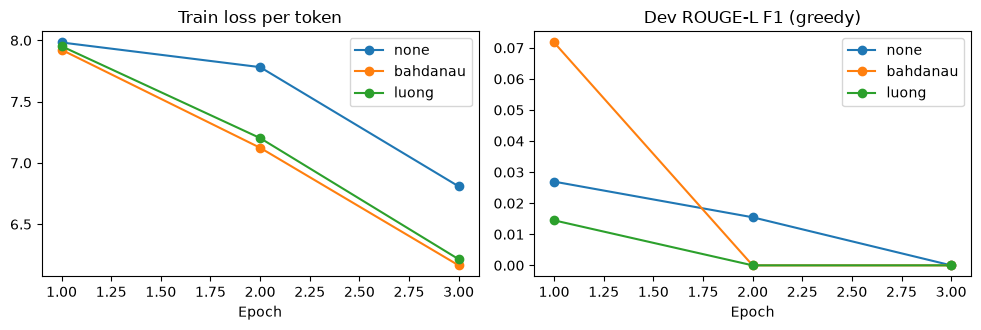

In [ ]:
# Vẽ loss train và ROUGE-L dev theo epoch
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for name, records in histories.items():
    h = pd.DataFrame(records)
    axes[0].plot(h.epoch, h.train_loss, marker='o', label=name)
    axes[1].plot(h.epoch, h.rougeL_f1, marker='o', label=name)
titles = ['Train loss per token', 'Dev ROUGE-L F1 (greedy)']
for ax, title in zip(axes, titles):
    ax.set_title(title)
    ax.set_xlabel('Epoch')
    ax.legend()
fig.tight_layout()
fig.savefig(ART/'learning_curves.png', dpi=150)
plt.show()

## B.7. Heatmap, checkpoint và đánh giá cuối

### Kiểm tra mô hình học thuộc một cặp câu tự tạo

Huấn luyện riêng một mô hình nhỏ trên duy nhất cặp “i love you” / “tôi yêu bạn”. Nếu mô hình không học thuộc được một câu thì có lỗi ở nhãn đích, trạng thái hoặc EOS. Điểm này không phải kết quả dịch máy.

In [ ]:
# Batch một cặp câu tự tạo và mô hình Bahdanau nhỏ
seed_all()
toy_row = dict(id=-1, src=tokens('i love you'), tgt=tokens('tôi yêu bạn'))
b = collate([toy_row])
src, tgt = b['src'].to(device), b['tgt'].to(device)
toy_cfg = dict(emb=32, hidden=32, layers=1, dropout=0.0)
toy_model = make_seq2seq('bahdanau', **toy_cfg)
optimizer = torch.optim.Adam(toy_model.parameters(), lr=0.02)

In [ ]:
# Huấn luyện 100 bước trên đúng một cặp câu
for _ in range(100):
    toy_model.train()
    optimizer.zero_grad(set_to_none=True)
    logits = toy_model(src, b['lengths'], tgt, teacher_ratio=1.0)
    loss = criterion(logits.reshape(-1, len(tgt_vocab)),
                     tgt[:, 1:].reshape(-1))
    loss.backward()
    nn.utils.clip_grad_norm_(toy_model.parameters(), 1.0)
    optimizer.step()
print('Loss cuối:', round(loss.item(), 6))

Loss cuối: 0.003336


In [ ]:
# Giải mã không teacher forcing: phải ra đúng "tôi yêu bạn"
predicted, toy_weights = generate(toy_model, src, b['lengths'], 8)
assert decode(predicted[0].cpu()) == 'tôi yêu bạn'
assert EOS in predicted[0].tolist()
print('Bản dịch tự sinh:', decode(predicted[0].cpu()))

Bản dịch tự sinh: tôi yêu bạn


### Vẽ heatmap attention và kiểm tra tổng trọng số

Heatmap lấy từ mô hình học thuộc cặp câu tự tạo ở bước trước: hàng là token được sinh, cột là token nguồn kể cả EOS. Trọng số attention là phân phối mềm, không phải căn chỉnh từ chính xác. Khi làm Phần C, dùng cùng đoạn code này cho mô hình đã huấn luyện.

In [ ]:
# Lấy ma trận attention tới EOS; mỗi hàng phải cộng bằng 1
shown_ids = predicted[0].cpu().tolist()
stop = shown_ids.index(EOS)+1 if EOS in shown_ids else len(shown_ids)
matrix = toy_weights[0, :stop, :b['lengths'][0]].cpu().numpy()
assert np.allclose(matrix.sum(-1), 1.0, atol=1e-6)
x_labels = toy_row['src']+['<eos>']
y_labels = [tgt_itos[i] for i in shown_ids[:stop]]
print('Tổng từng hàng attention:', np.round(matrix.sum(-1), 6).tolist())

Tổng từng hàng attention: [1.0, 1.0, 1.0, 1.0]


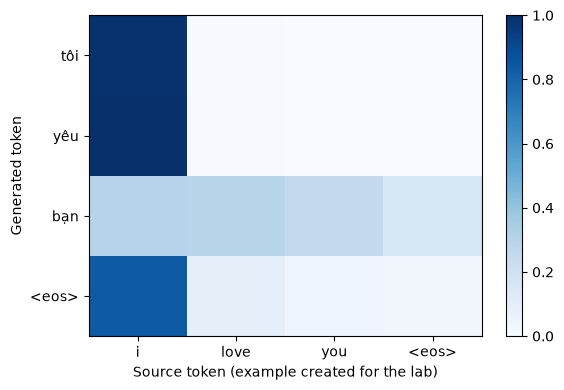

In [ ]:
# Vẽ heatmap: hàng là token sinh ra, cột là token nguồn
fig, ax = plt.subplots(figsize=(6, 4))
image = ax.imshow(matrix, cmap='Blues', aspect='auto', vmin=0, vmax=1)
ax.set_xticks(range(len(x_labels)), x_labels)
ax.set_yticks(range(len(y_labels)), y_labels)
ax.set_xlabel('Source token (example created for the lab)')
ax.set_ylabel('Generated token')
fig.colorbar(image, ax=ax)
fig.tight_layout()
fig.savefig(ART/'attention_toy.png', dpi=150)
plt.show()

### Lưu từ điển, cấu hình và nạp lại checkpoint

Trọng số phải đi kèm từ điển, id token đặc biệt, cách chuẩn hóa, id các cặp đã chọn và cấu hình kiến trúc. Nạp lại bằng `map_location` để chạy được trên CPU/GPU. So logits trước và sau khi nạp chỉ để kiểm tra trọng số, không phải điểm ROUGE-L.

In [ ]:
# Lưu cấu hình, từ điển và id các cặp đã dùng vào metadata.json
metadata = dict(config=cfg, seed=42, device=str(device),
                normalization='NFC; remove BOM; lowercase; whitespace',
                src_vocab=src_vocab, tgt_vocab=tgt_vocab, files=DATA_FILES,
                selected_train_ids=[r['id'] for r in train_rows],
                selected_dev_ids=[r['id'] for r in dev_rows],
                histories=histories, best_epochs=best_epochs)
text = json.dumps(metadata, ensure_ascii=False, indent=2)
(ART/'metadata.json').write_text(text, encoding='utf-8')
print('Đã lưu metadata.json và', len(models), 'checkpoint .pt')

Đã lưu metadata.json và 3 checkpoint .pt


In [ ]:
# Nạp lại checkpoint Bahdanau và so logits với mô hình đang có
restored = make_seq2seq('bahdanau')
state = torch.load(ART/'bahdanau.pt', map_location=device, weights_only=True)
restored.load_state_dict(state)
restored.eval()
b = collate(toy)
with torch.no_grad():
    args = (b['src'].to(device), b['lengths'], b['tgt'].to(device))
    a = restored(*args, teacher_ratio=1.0)
    c = models['bahdanau'](*args, teacher_ratio=1.0)
torch.testing.assert_close(a, c)
print('Nạp lại checkpoint, từ điển và metadata: PASS')

Nạp lại checkpoint, từ điển và metadata: PASS


### Chấm test một lần sau khi chốt mô hình

Chỉ chạy ô dưới khi đã chọn xong cấu hình và checkpoint bằng dev. Không dùng kết quả test để chỉnh siêu tham số; nếu sửa mô hình sau khi xem test thì phải ghi rõ trong báo cáo.

In [ ]:
# ROUGE-L trên toàn bộ test sau lọc của ba mô hình đã chọn
results = []
for name, model in models.items():
    score = evaluate(model, filtered['test'])
    score.pop('dev_nll')
    results.append(dict(model=name, **score))
results = pd.DataFrame(results)
results.to_csv(ART/'comparison_test.csv', index=False)
print(results.drop(columns='bleu_signature').round(4).to_string(index=False))

   model  rougeL_f1  rougeL_precision  rougeL_recall   bleu
    none     0.0223            0.0183         0.0307 0.0114
bahdanau     0.0923            0.7293         0.0499 0.0000
   luong     0.0134            0.0214         0.0116 0.0053


## Phần C. Bài tập về nhà

**Hướng dẫn nộp bài**

- Commit và push code lên GitHub, nộp file `<MSSV>.txt` chứa link GitHub lên courses.
- Notebook giữ nguyên output; kèm báo cáo ngắn (PDF) trình bày kết quả và nhận xét.
- Không đưa thư mục `data/` lên GitHub.

**Cấu hình chung cho các bài**

| Thông số | Giá trị |
| --- | --- |
| Encoder / Decoder | 3 lớp LSTM mỗi bên, hidden_size=256 |
| Embedding / dropout | 256 / 0.3 |
| Tối ưu | Adam, lr=1e-3, batch_size=32 |
| Số epoch | Tối đa 10, giữ checkpoint có ROUGE-L dev cao nhất |
| Dữ liệu | small-PhoMT, giữ câu ≤ 50 từ; dùng toàn bộ train/dev/test |
| Độ đo | ROUGE-L (F1) trên tập test |

Trong notebook chỉ cần sửa `cfg` theo các chú thích `Phần C` rồi Restart Kernel và Run All.

### Bài 1. Encoder–Decoder LSTM

**Yêu cầu:** Xây dựng kiến trúc Encoder–Decoder gồm 3 lớp LSTM cho encoder và 3 lớp LSTM cho decoder, hidden size 256, cho bài toán dịch máy từ tiếng Anh sang tiếng Việt. Huấn luyện bằng Adam trên small-PhoMT và đánh giá bằng ROUGE-L.

**Kết quả cần nộp:** ROUGE-L trên tập test; đồ thị loss train và ROUGE-L dev theo epoch; 3 câu dịch mẫu (đúng và sai) kèm nhận xét.

**Gợi ý:** Dùng `make_seq2seq('none')` ở B.4 và hàm `fit` ở B.5.

### Bài 2. Encoder–Decoder LSTM với Bahdanau attention

**Yêu cầu:** Như Bài 1, nhưng decoder có attention theo bài báo “Neural Machine Translation by Jointly Learning to Align and Translate” (Bahdanau và cộng sự).

**Kết quả cần nộp:** Như Bài 1, thêm heatmap attention của 3 câu và nhận xét.

**Gợi ý:** Dùng `make_seq2seq('bahdanau')`; vẽ heatmap bằng code ở B.7.

### Bài 3. Encoder–Decoder LSTM với Luong attention

**Yêu cầu:** Như Bài 1, nhưng decoder có attention theo bài báo “Effective Approaches to Attention-based Neural Machine Translation” (Luong và cộng sự).

**Kết quả cần nộp:** Như Bài 1, thêm bảng so sánh ba mô hình (bảng dưới) và nhận xét mô hình nào tốt hơn, vì sao.

**Gợi ý:** Dùng `make_seq2seq('luong')`. Giữ nguyên cấu hình chung để so sánh công bằng.

### Bảng tổng hợp kết quả

| Mô hình | ROUGE-L dev | ROUGE-L test | Số tham số | Giây/epoch |
| --- | --- | --- | --- | --- |
| Bài 1. Không attention |  |  |  |  |
| Bài 2. Bahdanau |  |  |  |  |
| Bài 3. Luong |  |  |  |  |